# Clasificación: CatBoost

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from Modelado import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_CLF, ESTRATEGIAS, N_ITER_FASE1,
    cargar_split, separar_x_y, crear_cv, dispositivo_modelo, verificar_smotenc,
    describir_espacio, ejecutar_fase1, formatear_tabla_cv, graficar_estrategias, elegir_mejor, guardar_fase1,
    formatear_hiperparametros, tabla_hiperparametros,
)

CLAVE = "catboost"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_modelo(CLAVE),
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,CatBoost
USAR_GPU,False
GPU detectada por librería,ninguna
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y(df_train)
cv = crear_cv(SEED)

pd.DataFrame({
    "Filas": [len(X_train)],
    "Predictores": [X_train.shape[1]],
    "Deprimidos": [int(y_train.sum())],
    "Prevalencia": [round(y_train.mean(), 3)],
}, index=pd.Index(["Train"], name="Conjunto"))

,Filas,Predictores,Deprimidos,Prevalencia
Conjunto,,,,
Train,3848,6,630,0.164


### Estrategias de Manejo del Desbalance

| Estrategia | Qué hace | En CatBoost |
|---|---|---|
| **a) Nativo** | Sin balanceo: el modelo ve la proporción real (16% de positivos). | — |
| **b) Pesos de clase** | Los errores en la clase minoritaria pesan más al entrenar. | `auto_class_weights="Balanced"` |
| **c) SMOTENC** | Genera deprimidos sintéticos a partir de sus vecinos deprimidos más cercanos, hasta igualar las clases. Sin pesos de clase. | `SMOTENC(categorical_features=["sex"], random_state=42)` |

In [4]:
tabla_clases, tabla_sexo = verificar_smotenc(X_train, y_train, seed=SEED)
display(tabla_clases)
display(tabla_sexo)

✓ sex solo toma los valores ['Boy', 'Girl']
✓ Clases balanceadas: {0: 3218, 1: 3218}


,Antes,Después,Sintéticos
Deprimido,,,
0,3218,3218,0
1,630,3218,2588


Deprimido,0,1
Sexo,,
Boy,1789,770
Girl,1429,2448


### Espacio de Búsqueda

Se exploraron 25 combinaciones aleatorias por estrategia. Se variaron la complejidad del modelo (profundidad de 3 a 7 y entre 200 y 800 iteraciones), la regularización L2 de las hojas (`l2_leaf_reg` de 1 a 10) y la tasa de aprendizaje en escala logarítmica (0.01 a 0.2).

In [5]:
describir_espacio(CLAVE).style.set_caption(f"Combinaciones por estrategia: {N_ITER_FASE1[CLAVE]}")

,Valores
Hiperparámetro,
iterations,entero entre 200 y 800
depth,entero entre 3 y 7
learning_rate,log-uniforme entre 0.01 y 0.2
l2_leaf_reg,uniforme entre 1 y 10


### Validación Cruzada por Estrategia

Para cada estrategia se ejecuta un `RandomizedSearchCV` **solo sobre el train**, con los mismos folds y `scoring` PR-AUC (`average_precision`).

In [6]:
tabla, pipelines, hiperparametros = ejecutar_fase1(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo (sin balanceo)  PR-AUC = 0.4057 ± 0.0530  (16 s)
✓ Pesos de clase         PR-AUC = 0.3970 ± 0.0491  (13 s)
✓ SMOTENC                PR-AUC = 0.3927 ± 0.0462  (21 s)


In [7]:
vista = formatear_tabla_cv(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
vista.rename(index=ESTRATEGIAS)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Tiempo (s)
Estrategia,,,,,,,
Nativo (sin balanceo),0.406 ± 0.053,0.751 ± 0.030,0.590 ± 0.118,0.132 ± 0.015,0.214 ± 0.022,0.842 ± 0.006,16.0
Pesos de clase,0.397 ± 0.049,0.748 ± 0.027,0.305 ± 0.025,0.637 ± 0.046,0.412 ± 0.032,0.702 ± 0.019,13.0
SMOTENC,0.393 ± 0.046,0.747 ± 0.026,0.397 ± 0.042,0.433 ± 0.026,0.414 ± 0.034,0.798 ± 0.017,21.0


*Pendiente: interpretar tras ejecutar el notebook.* Comparar la PR-AUC y la ROC-AUC de las estrategias y si sus desviaciones se solapan.

*Pendiente: interpretar tras ejecutar el notebook.* Precision, recall, F1 y accuracy con umbral 0.5 por estrategia; comparar la accuracy con la de predecir siempre “no deprimido” (1 − 0.164 = 0.836).

In [8]:
# Mejores hiperparámetros por estrategia
tabla_hiperparametros(hiperparametros)

,depth,iterations,l2_leaf_reg,learning_rate
Estrategia,,,,
Nativo (sin balanceo),4,232,1.572,0.02539
Pesos de clase,4,232,1.572,0.02539
SMOTENC,4,232,1.572,0.02539


*Pendiente: interpretar tras ejecutar el notebook.* Qué configuración eligió cada estrategia y qué sugiere sobre la complejidad de la señal.

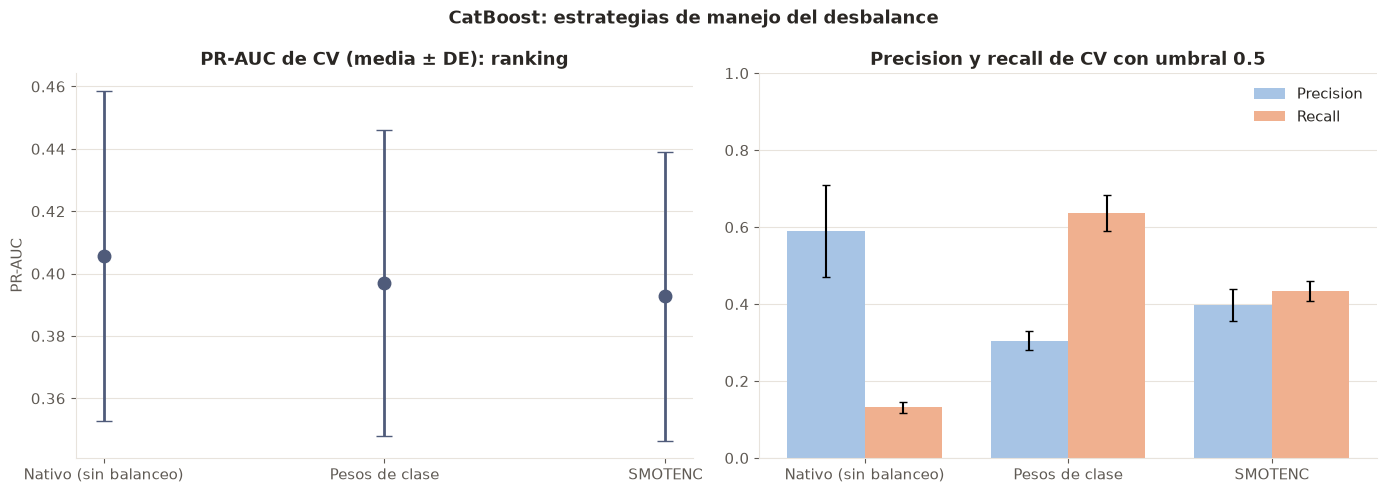

In [9]:
fig = graficar_estrategias(tabla, NOMBRES_CLF[CLAVE])
plt.show()

*Pendiente: interpretar tras ejecutar el notebook.* Si las barras de PR-AUC se solapan y cómo cambia el punto de operación (precision vs. recall) con umbral 0.5.

### Selección del Mejor Modelo CatBoost

Se elige la estrategia con **mayor PR-AUC media de CV**.

In [10]:
estrategia_ganadora, explicacion = elegir_mejor(tabla)

pd.Series({
    "Estrategia ganadora": ESTRATEGIAS[estrategia_ganadora],
    "PR-AUC de CV": f"{tabla.loc[estrategia_ganadora, 'PR-AUC media']:.4f} ± {tabla.loc[estrategia_ganadora, 'PR-AUC DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[estrategia_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,CatBoost
Estrategia ganadora,Nativo (sin balanceo)
PR-AUC de CV,0.4057 ± 0.0530
Hiperparámetros,"depth=4, iterations=232, l2_leaf_reg=1.572, learning_rate=0.02539"
Criterio,Se elige 'nativo': tiene la mayor PR-AUC media de CV (0.4057 ± 0.0530).


*Pendiente: interpretar tras ejecutar el notebook.* Qué estrategia se eligió, qué tan lejos quedaron las demás frente a la desviación entre folds y qué implica su recall con umbral 0.5 (el umbral se optimiza en la fase 3).

### Guardado

In [11]:
ganador = guardar_fase1(
    CLAVE, tabla, estrategia_ganadora, pipelines[estrategia_ganadora],
    hiperparametros[estrategia_ganadora], explicacion,
)